---
title: "Лабораторна робота 4. Виявлення та валідація прихованої структури і закономірностей у даних"
description: "Машинне навчання та методи вилучення знань | PhD F3 «Комп'ютерні науки» | КрНУ ім. М. Остроградського"
author: "&copy; [Valeriy Sydorenko](https://www.linkedin.com/in/valeriy-sydorenko-6782279a/), 2026"
date: today
jupyter: python3
bibliography: mlkdd-references.bib

format:
  html:
    code-fold: show
    code-summary: "Показати код"
    code-overflow: wrap
    toc: true
    toc-depth: 4
    toc-location: right
    number-sections: false
    embed-resources: true
    smooth-scroll: true
---


::: {.callout-note}
## Місце роботи в курсі

ЛР1 -- *Research Specification v0.1*; ЛР2 -- *Experiment Design v0.2*; ЛР3 -- *Validation & Evidence Audit v0.3*.

У ЛР4 розширюємо наскрізне дослідження: перевіряємо, чи існує у даних відносно стійка структура, яку можна змістовно інтерпретувати. Результат -- *Structure Discovery & Validation v0.4*.
:::

## Мета роботи

Набути практичних навичок виявлення прихованої структури даних методами навчання без учителя (unsupervised learning), перевірки стійкості знайдених закономірностей до вибору представлення, алгоритму та складу вибірки, а також формулювання науково обґрунтованих висновків з урахуванням альтернативних пояснень.

## Завдання роботи

1. Підготувати відтворюваний навчальний набір даних.
2. Проаналізувати вплив масштабу та геометрії ознак.
3. Побудувати представлення за допомогою методу головних компонент (PCA).
4. Виконати кластеризацію методом k-середніх (k-means).
5. Порівняти внутрішні критерії для різних значень кількості кластерів.
6. Перевірити стійкість розбиття за зміни складу вибірки.
7. Порівняти результат із нульовою моделлю.
8. Відокремити алгоритмічний результат від наукового твердження.
9. Перенести процедуру на власну дисертаційну задачу.

## Теоретичні відомості

Метод головних компонент (principal component analysis, PCA) знаходить ортогональні напрями максимальної дисперсії. Для центрованої матриці $X_c$ матриця вибіркових коваріацій має вигляд

$$
S=\frac{1}{n-1}X_c^\top X_c.
$$

Власні вектори $S$ задають напрями головних компонент, а власні значення характеризують дисперсію вздовж цих напрямів.

Метод k-середніх (k-means) мінімізує внутрішньокластерну суму квадратів:

$$
J=\sum_{k=1}^{K}\sum_{i\in C_k}\|x_i-\mu_k\|_2^2.
$$

Однак мінімізація $J$ *не доводить* існування природних класів. Кількість $K$, метрика, масштабування та вибір ознак є дослідницькими припущеннями [@hastie2009elements; @bishop2006prml].

Для об'єкта $i$ коефіцієнт силуету (silhouette coefficient):

$$
s(i)=\frac{b(i)-a(i)}{\max\{a(i),b(i)\}},
$$

де $a(i)$ -- середня відстань до об'єктів власного кластера, $b(i)$ -- мінімальна середня відстань до іншого кластера.

Стабільність розбиття можна оцінити скоригованим індексом Ренда (adjusted Rand index, ARI), який інваріантний до перестановки номерів кластерів.

### Методологічний ланцюг

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Дослідницьке<br/>питання") --> B("Представлення<br/>та метрика")
 B --> C("PCA та<br/>кластеризація")
 C --> D("Внутрішня<br/>валідація")
 D --> E("Стабільність<br/>і нульова модель")
 E --> F("Предметна<br/>інтерпретація")
 F --> G("Evidence<br/>v0.4")
```

# Частина I. Навчальний експеримент

## 1. Постановка дослідницького питання

На синтетичному наборі даних перевіримо гіпотезу:

> Чи відтворюється кластерна структура за обґрунтованих змін представлення та вибірки, і чи відрізняється її геометрична виразність від результату нульової моделі?

Генератор створює три групи у двох інформативних вимірах і додає шумові ознаки. Мітки генератора використовуємо *лише для додаткової зовнішньої перевірки*, а не для вибору $K$.

::: {.callout-warning}
## Межа інтерпретації

Цей приклад є контрольованим синтетичним експериментом. Його результати не свідчать про існування аналогічних груп у реальній предметній області.
:::

## 2. Генерація та первинний аудит даних


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.model_selection import ShuffleSplit

SEED = 42
rng = np.random.default_rng(SEED)

X_signal, y_true = make_blobs(
    n_samples=360,
    centers=3,
    cluster_std=[0.65, 0.8, 0.7],
    random_state=SEED
)
X = np.column_stack([
    X_signal,
    rng.normal(size=(len(X_signal), 5))
])
feature_names = ["signal_1", "signal_2"] + [
    f"noise_{i}" for i in range(1, 6)
]
df = pd.DataFrame(X, columns=feature_names)

print("Розмір вибірки:", df.shape)
print("Пропуски:", int(df.isna().sum().sum()))
display(df.describe().round(3))


Розмір вибірки: (360, 7)
Пропуски: 0


,signal_1,signal_2,noise_1,noise_2,noise_3,noise_4,noise_5
count,360.000,360.000,360.000,360.000,360.000,360.000,360.000
mean,-1.606,1.372,-0.023,-0.026,-0.007,-0.053,-0.099
std,4.876,6.564,0.970,1.034,0.971,1.045,1.004
min,-8.767,-8.428,-2.481,-2.867,-2.956,-2.778,-3.648
25%,-6.514,-6.374,-0.703,-0.724,-0.654,-0.739,-0.735
50%,-2.532,1.927,-0.047,0.006,0.044,-0.013,-0.069
75%,4.069,8.592,0.599,0.632,0.556,0.638,0.542
max,7.103,11.519,2.387,3.179,2.809,2.905,2.914


### Завдання 2.1

Поясніть, чому наявність у генераторі трьох груп не дає права автоматично обрати $K=3$ як «відкритий» результат. Які властивості набору даних відомі нам лише завдяки контрольованому генератору?

## 3. Геометрія ознак та PCA

Стандартизація змінює відносні внески ознак у відстань. Порівняємо частку дисперсії, пояснену першими двома головними компонентами, та побудуємо проєкцію.


EVR: [0.206 0.16 ]
Сумарна EVR: 0.365


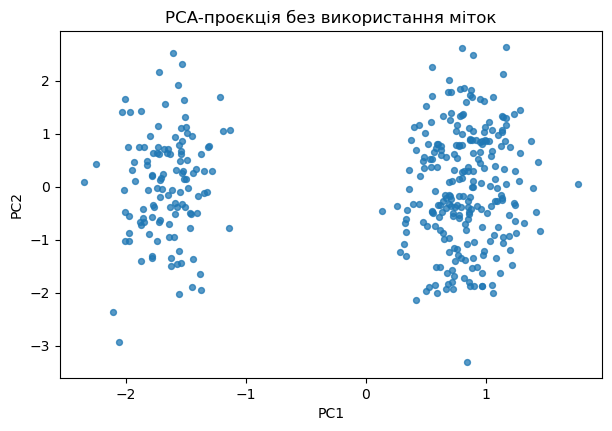

In [2]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
Z = pca.fit_transform(X_scaled)

print("EVR:", pca.explained_variance_ratio_.round(3))
print("Сумарна EVR:", round(pca.explained_variance_ratio_.sum(), 3))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(Z[:, 0], Z[:, 1], s=18, alpha=0.75)
ax.set(xlabel="PC1", ylabel="PC2",
       title="PCA-проєкція без використання міток")
plt.show()


### Завдання 3.1

Чи можна за двовимірною проєкцією однозначно визначити число кластерів у повному просторі? Поясніть різницю між *поясненою дисперсією* та *відокремленістю груп*.

## 4. Кластеризація та вибір кількості кластерів

Порівняємо $K=2,\ldots,7$ за silhouette. Критерій обчислюємо в тому просторі, де виконуємо кластеризацію: у стандартизованому повному просторі, а не на PCA-графіку.


C:\Users\Valeriy\miniconda3\envs\ml-mke\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


,K,silhouette,inertia
0,2,0.217,2014.629
1,3,0.167,1813.421
2,4,0.157,1683.379
3,5,0.139,1579.447
4,6,0.153,1472.369
5,7,0.151,1403.966


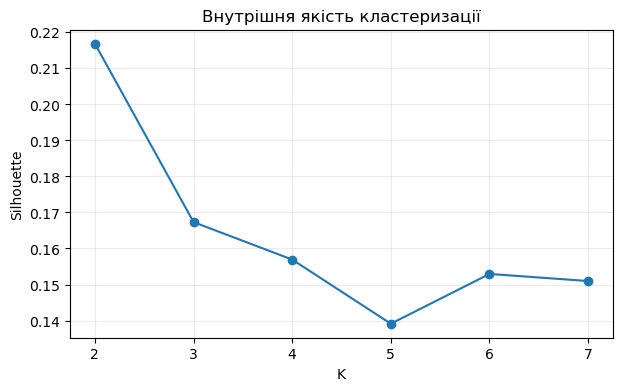

In [3]:
rows = []
for k in range(2, 8):
    model = KMeans(n_clusters=k, n_init=20, random_state=SEED)
    labels = model.fit_predict(X_scaled)
    rows.append({
        "K": k,
        "silhouette": silhouette_score(X_scaled, labels),
        "inertia": model.inertia_
    })
scores = pd.DataFrame(rows)
display(scores.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(scores["K"], scores["silhouette"], marker="o")
ax.set(xlabel="K", ylabel="Silhouette",
       title="Внутрішня якість кластеризації")
ax.grid(alpha=0.25)
plt.show()


### Завдання 4.1

Оберіть $K$ за внутрішнім критерієм. Чи збігається він із кількістю груп, закладеною генератором? Якщо ні -- поясніть, чому це не обов'язково є програмною помилкою.

## 5. Чутливість до представлення

Порівняємо кластеризацію у трьох просторах: вихідні ознаки без масштабування, стандартизовані ознаки та дві PCA-компоненти. Для контрольованого порівняння фіксуємо $K=3$ *лише як демонстраційний параметр*.


In [4]:
spaces = {
    "raw": X,
    "scaled": X_scaled,
    "PCA-2": Z
}
labels_by_space = {}
space_rows = []

for name, features in spaces.items():
    labels = KMeans(
        n_clusters=3, n_init=20, random_state=SEED
    ).fit_predict(features)
    labels_by_space[name] = labels
    space_rows.append({
        "space": name,
        "silhouette": silhouette_score(features, labels),
        "ARI_vs_generator": adjusted_rand_score(y_true, labels)
    })

display(pd.DataFrame(space_rows).round(3))


,space,silhouette,ARI_vs_generator
0,raw,0.716,1.000
1,scaled,0.167,0.538
2,PCA-2,0.540,0.497


::: {.callout-important}
## Інтерпретація

Значення silhouette у різних просторах не завжди безпосередньо порівнювані: змінюється сама геометрія відстаней. У таблиці ARI з мітками генератора -- *навчальна зовнішня перевірка*, а не критерій, доступний у звичайному дослідженні без учителя.
:::

### Завдання 5.1

Поясніть, як змінюється висновок залежно від вибору представлення. Яке представлення було б виправданим для Вашого дослідницького питання?

## 6. Стабільність кластеризації за зміни вибірки

Навчимо моделі на різних підвибірках і порівняємо їхні прогнози на *одній фіксованій референсній множині*. Безпосередньо порівнювати кластерні мітки різних наборів об'єктів некоректно.


count    14.000
mean      0.599
std       0.030
min       0.563
25%       0.567
50%       0.619
75%       0.619
max       0.640
Name: ARI, dtype: float64


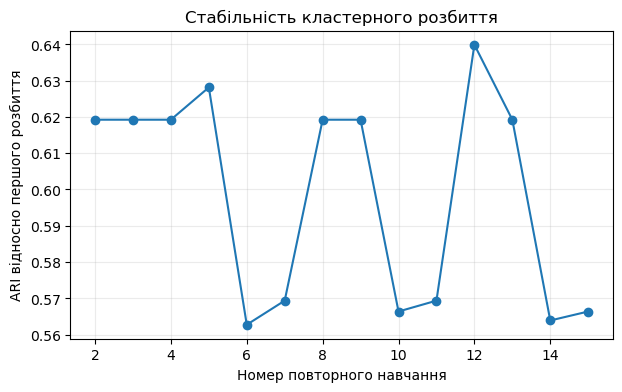

In [5]:
splitter = ShuffleSplit(
    n_splits=15, train_size=0.8, random_state=SEED
)
reference = X_scaled[:100]
reference_labels = []

for train_idx, _ in splitter.split(X_scaled):
    km = KMeans(n_clusters=3, n_init=20, random_state=SEED)
    km.fit(X_scaled[train_idx])
    reference_labels.append(km.predict(reference))

stability = [
    adjusted_rand_score(reference_labels[0], labels)
    for labels in reference_labels[1:]
]
print(pd.Series(stability, name="ARI").describe().round(3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(2, len(reference_labels) + 1), stability, marker="o")
ax.set(xlabel="Номер повторного навчання",
       ylabel="ARI відносно першого розбиття",
       title="Стабільність кластерного розбиття")
ax.grid(alpha=0.25)
plt.show()


### Завдання 6.1

Чи означає високе ARI, що знайдені кластери відповідають природним категоріям? Яку саме стабільність перевірено, а які джерела невизначеності залишилися?

## 7. Нульова модель (null model)

Навіть без природних кластерів k-means поверне розбиття. Побудуємо нульову модель шляхом незалежного перемішування кожної ознаки. Така процедура зберігає одномірні емпіричні розподіли, але руйнує міжознакові залежності.

Порівняємо silhouette за фіксованого $K=3$; це перевірка *конкретної нульової гіпотези*, а не універсальний тест «існування кластерів».


Observed silhouette: 0.167
Null mean: 0.119
Null SD: 0.004
Monte Carlo tail proportion: 0.024


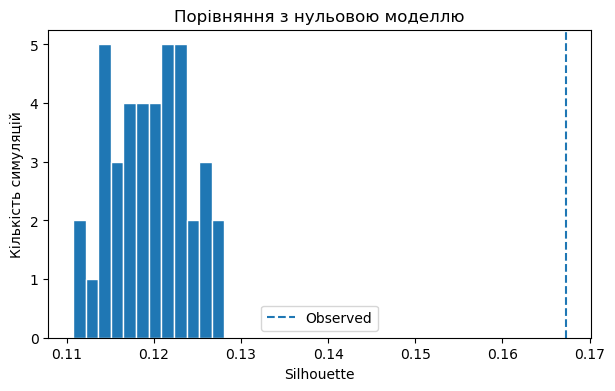

In [6]:
observed_labels = KMeans(
    n_clusters=3, n_init=20, random_state=SEED
).fit_predict(X_scaled)
observed_score = silhouette_score(X_scaled, observed_labels)

rng_null = np.random.default_rng(SEED + 10)
null_scores = []
B = 40

for b in range(B):
    X_null = np.column_stack([
        rng_null.permutation(X_scaled[:, j])
        for j in range(X_scaled.shape[1])
    ])
    null_labels = KMeans(
        n_clusters=3, n_init=10, random_state=SEED + b
    ).fit_predict(X_null)
    null_scores.append(silhouette_score(X_null, null_labels))

null_scores = np.asarray(null_scores)
p_empirical = (1 + np.sum(null_scores >= observed_score)) / (B + 1)

print("Observed silhouette:", round(observed_score, 3))
print("Null mean:", round(null_scores.mean(), 3))
print("Null SD:", round(null_scores.std(ddof=1), 3))
print("Monte Carlo tail proportion:", round(p_empirical, 3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(null_scores, bins=12, edgecolor="white")
ax.axvline(observed_score, linestyle="--", label="Observed")
ax.set(xlabel="Silhouette", ylabel="Кількість симуляцій",
       title="Порівняння з нульовою моделлю")
ax.legend()
plt.show()


### Завдання 7.1

Яку саме структуру руйнує обрана нульова модель? Чи можна за малим значенням емпіричної хвостової частки робити висновок про наявність предметно значущих категорій?

Поясніть обмеження: кількість симуляцій $B$, фіксоване $K$, вибір нульового механізму, відсутність незалежної зовнішньої перевірки.

## 8. Матриця валідності виявленої структури

| Загроза | Механізм | Перевірка | Межа висновку |
|---|---|---|---|
| Масштаб ознак | Домінування окремих координат | Raw vs scaled | |
| Вибір представлення | Втрата/зміна відстаней | Scaled vs PCA | |
| Кількість кластерів | Залежність від $K$ | Silhouette для кількох $K$ | |
| Випадкова вибірка | Нестійкі групи | Subsampling + ARI | |
| Алгоритмічний артефакт | Кластери виникають завжди | Null model | |
| Постфактум-інтерпретація | Неперевірені назви груп | Предметні змінні | |

### Завдання 8.1

Сформулюйте три рівні висновку: *алгоритмічний результат*, *емпірична закономірність* і *наукове твердження*. Позначте, який рівень реально підтримується Вашими обчисленнями.

# Частина II. Перенесення на дисертаційне дослідження

## 9. Дослідницьке питання та тип структури

Поверніться до *Validation & Evidence Audit v0.3*. Сформулюйте, яку структуру Ви шукаєте: кластери, латентні фактори, градієнти, підпростори, графові спільноти або часові режими. Якщо виявлення структури не є самостійною задачею Вашої дисертації, визначте його роль як допоміжного аналізу.

## 10. Протокол представлення

Зафіксуйте одиницю аналізу, набір ознак, масштабування, метрику близькості, метод зменшення розмірності (якщо потрібний) та припущення про форму структури.

| Елемент | Рішення | Наукове обґрунтування |
|---|---|---|
| Одиниця аналізу | | |
| Ознаки/представлення | | |
| Масштабування | | |
| Метрика близькості | | |
| Метод пошуку структури | | |
| Кількість компонент/кластерів | | |

## 11. Виявлення та внутрішня перевірка

Реалізуйте хоча б один обґрунтований метод виявлення структури та один внутрішній критерій. Не обирайте метод лише за найбільшою метрикою: зазначте припущення і практичну інтерпретацію.

## 12. Стабільність і нульова модель

Перевірте стійкість хоча б до *одного* дослідницьки виправданого збурення: зміна вибірки, допустима зміна метрики, складу ознак або ініціалізації. Сконструюйте нульову модель, яка руйнує саме ту залежність, що є предметом RQ.

Для часових, графових та групованих даних *не застосовуйте автоматично* незалежне перемішування рядків чи ознак: воно може руйнувати суттєву структуру даних і робити нульову модель неадекватною.

## 13. Предметна інтерпретація

Описуйте кластери через незалежні або наперед визначені предметні характеристики. Не надавайте групам назв, що містять причинні чи нормативні судження, якщо вони не підтверджені окремими доказами.

## 14. Підсумковий артефакт

Підготуйте **Structure Discovery & Validation v0.4**:

1. Дослідницьке питання й тип структури.
2. Дані, одиниця аналізу, представлення.
3. Алгоритм і зафіксовані параметри.
4. Внутрішній критерій та його інтерпретація.
5. Перевірка стійкості.
6. Нульова модель або предметно обґрунтована альтернатива.
7. Предметна інтерпретація й альтернативні пояснення.
8. Підтримуване твердження та межі узагальнення.

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Specification<br/>v0.1") --> B("Experiment<br/>v0.2")
 B --> C("Evidence Audit<br/>v0.3")
 C --> D("Structure<br/>Validation v0.4")
 D --> E("Наукове<br/>твердження")
```

# Контрольні питання

1. Чому результат кластеризації не є автоматично науковою закономірністю?
2. Яку роль відіграють масштабування та метрика?
3. Що максимізує PCA?
4. Чому висока частка поясненої дисперсії не гарантує кластерної структури?
5. Що мінімізує k-means?
6. Що вимірює silhouette?
7. Чому вибір $K$ є дослідницьким рішенням?
8. Чим внутрішня валідація відрізняється від зовнішньої?
9. Чому ARI придатний для порівняння переставлених кластерних міток?
10. Навіщо потрібна фіксована референсна множина при перевірці стабільності?
11. Що перевіряє нульова модель?
12. Чому нульова модель має відповідати структурі даних?
13. Які загрози виникають під час інтерпретації PCA-графіка?
14. Яке наукове твердження підтримує стабільна структура, а яке -- ні?

# Вимоги до звіту

Звіт повинен містити результати навчального експерименту, таблиці порівняння представлень і значень $K$, оцінку стабільності, результати нульової моделі, матрицю загроз валідності та власний *Structure Discovery & Validation v0.4*. Основна увага -- на доказовому ланцюгу, а не на обсязі коду.

# Висновки

Виявлення структури -- це перевірювана дослідницька гіпотеза. Внутрішні метрики, стійкість і нульові моделі надають різні, взаємодоповнювальні свідчення, але не замінюють предметної інтерпретації та незалежної валідації.

У ЛР5 переходимо до інтерпретації та дослідження поясненності моделей машинного навчання.

# Література

Основні джерела: [@hastie2009elements; @bishop2006prml; @breiman2001two].

::: {#refs}
:::
